In [475]:
# generell numerikk og nyttige funksjoner
import numpy as np
import pandas as pd

# plotting
import matplotlib.pyplot as plt
import seaborn as sns

# regresjon
import statsmodels.api as sm
import statsmodels.formula.api as smf

Hypotese 1: Veksten av Pokemon gjennom evolusjon følger kvadrat-kube-loven.
Dette vil si at vi ser om stigningstallet til høyden er 3. Altså om variabelen β₁ = 3. 

In [476]:
# lese inn datasett
pokedex = pd.read_csv("pokemon.csv")

# skriv ut første og siste radene
print(pokedex)

        id          name  height_m  weight_kg     type1    type2  generation  \
0        1     bulbasaur       0.7        6.9     grass   poison           1   
1        2       ivysaur       1.0       13.0     grass   poison           1   
2        3      venusaur       2.0      100.0     grass   poison           1   
3        4    charmander       0.6        8.5      fire      NaN           1   
4        5    charmeleon       1.1       19.0      fire      NaN           1   
...    ...           ...       ...        ...       ...      ...         ...   
1020  1021   raging-bolt       5.2      480.0  electric   dragon           9   
1021  1022  iron-boulder       1.5      162.5      rock  psychic           9   
1022  1023    iron-crown       1.6      156.0     steel  psychic           9   
1023  1024     terapagos       0.2        6.5    normal      NaN           9   
1024  1025     pecharunt       0.3        0.3    poison    ghost           9   

      evolves_from_id  
0              

In [477]:
pokedex = pokedex.astype({'type1':'category', 'type2':'category', 'generation':'category'})

print(pokedex["type1"].value_counts())

type1
water       134
normal      118
grass       103
bug          83
fire         66
psychic      60
electric     59
rock         58
dark         45
poison       42
fighting     40
ground       40
dragon       37
steel        36
ghost        35
ice          31
fairy        29
flying        9
Name: count, dtype: int64


In [478]:
pokedex.describe()

,id,height_m,weight_kg,evolves_from_id
count,1025.000000,1025.000000,1025.000000,484.000000
mean,513.000000,1.211610,66.987024,451.061983
std,296.036315,1.248167,121.272854,290.950261
min,1.000000,0.100000,0.100000,1.000000
25%,257.000000,0.500000,8.500000,192.500000
50%,513.000000,1.000000,28.000000,423.500000
75%,769.000000,1.500000,70.000000,692.500000
max,1025.000000,20.000000,999.900000,1012.000000


In [479]:
pokedex.dtypes

id                    int64
name                    str
height_m            float64
weight_kg           float64
type1              category
type2              category
generation         category
evolves_from_id     float64
dtype: object

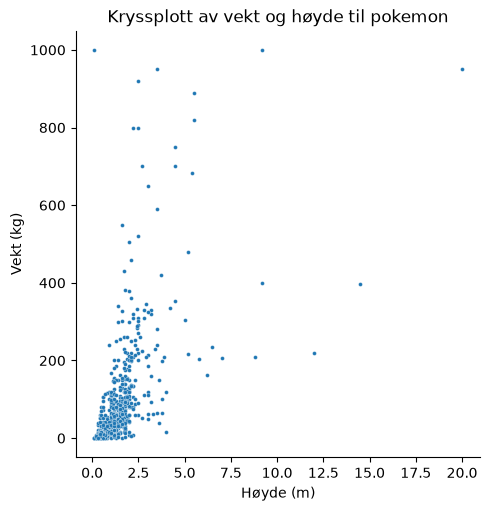

In [480]:
sns.relplot(x = 'height_m', y = 'weight_kg', kind = 'scatter', s = 8, data = pokedex)
plt.xlabel("Høyde (m)")
plt.ylabel("Vekt (kg)")
plt.title("Kryssplott av vekt og høyde til pokemon")
plt.show()

In [481]:
forrige = pokedex[["id", "name", "height_m", "weight_kg"]]
pairs = pokedex.merge(forrige, left_on="evolves_from_id", right_on="id", suffixes=("", "_prev"))

pairs["log_h_ratio"] = np.log(pairs["height_m"] / pairs["height_m_prev"])
pairs["log_w_ratio"] = np.log(pairs["weight_kg"] / pairs["weight_kg_prev"])
pairs["normal"] = ((pairs["type1"] == "normal") | (pairs["type2"] == "normal")).astype(int)

print("Antall evolusjoner:", len(pairs), "| Normal-type:", pairs["normal"].sum())
pairs[["name_prev", "name", "log_h_ratio", "log_w_ratio", "normal"]].head()

Antall evolusjoner: 484 | Normal-type: 58


,name_prev,name,log_h_ratio,log_w_ratio,normal
0,bulbasaur,ivysaur,0.356675,0.633428,0
1,ivysaur,venusaur,0.693147,2.040221,0
2,charmander,charmeleon,0.606136,0.804373,0
3,charmeleon,charizard,0.435318,1.560911,0
4,squirtle,wartortle,0.693147,0.916291,0


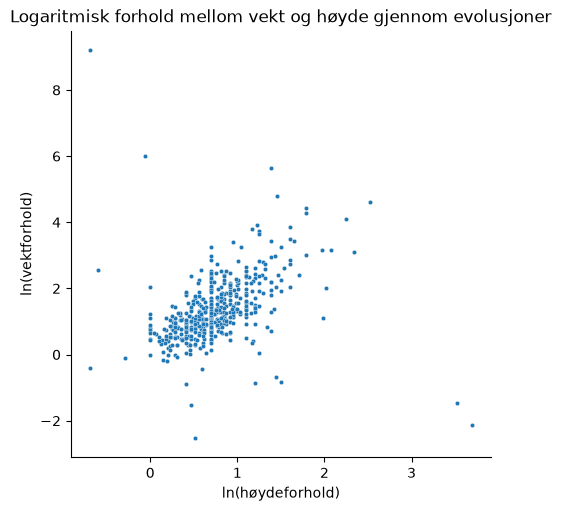

In [482]:
# plotter logaritmen av høydeforholdet og vektforholdet for hvert evolusjonssteg
sns.relplot(x = 'log_h_ratio', y = 'log_w_ratio', kind = 'scatter', s = 10, data = pairs)
plt.xlabel("ln(høydeforhold)")
plt.ylabel("ln(vektforhold)")
plt.title("Logaritmisk forhold mellom vekt og høyde gjennom evolusjoner")
plt.show()

In [483]:
formel = 'log_w_ratio ~ log_h_ratio'

modell = smf.ols(formel, data=pairs)
resultat = modell.fit()

print(resultat.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     60.18
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.20e-14
Time:                        13:37:18   Log-Likelihood:                -662.84
No. Observations:                 484   AIC:                             1330.
Df Residuals:                     482   BIC:                             1338.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.7890      0.084      9.402      

In [484]:
print(resultat.conf_int())
print(resultat.t_test("log_h_ratio = 3"))

                    0         1
Intercept    0.624131  0.953903
log_h_ratio  0.554394  0.930488
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.7424      0.096    -23.589      0.000       0.554       0.930


Det er flere ting i modellen som gjør at vi må forkaste hypotesen.
H0: β₁ = 3, H1: β₁ ≠ 3

Slik vi ser er det estimerte stigningstallet β₁ = 0,74, som er langt unna hva kvadrat-kube-loven tilsier på en verdi av 3.
Vi finner heller ikke 3 i konfidensintervallet [0,55, 0,93], og t-testen gir t = −23,6 og p < 0,001.

Loven tilsier også at konstantleddet β₀ skal være 0. Vi får β₀ = 0,79 med konfidensintervall [0,62, 0,95], så det stemmer heller ikke.

Så dette betyr at vekten øker langt mindre med høyden enn hva kvadrat-kube-loven tilsier.

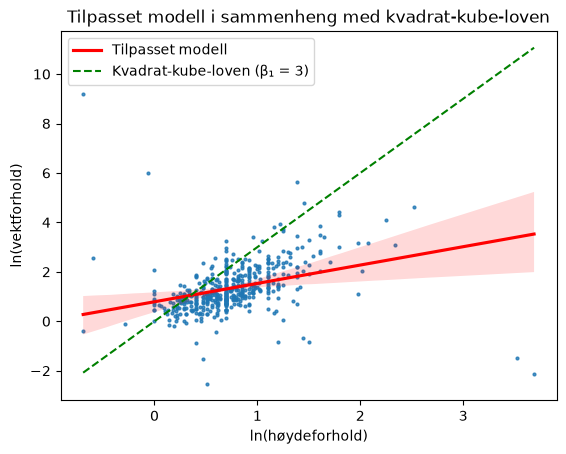

In [485]:
sns.regplot(x="log_h_ratio", y="log_w_ratio", data=pairs, line_kws={"color": "red", "label": "Tilpasset modell"}, scatter_kws={"s": 4})
x = np.linspace(pairs["log_h_ratio"].min(), pairs["log_h_ratio"].max(), 100)

plt.plot(x, 3 * x, color = "green", linestyle = "--", label = "Kvadrat-kube-loven (β₁ = 3)")
plt.xlabel("ln(høydeforhold)")
plt.ylabel("ln(vektforhold)")
plt.title("Tilpasset modell i sammenheng med kvadrat-kube-loven")
plt.legend()
plt.show()

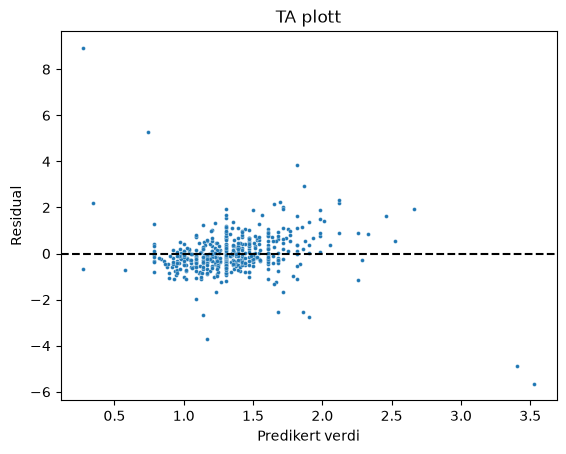

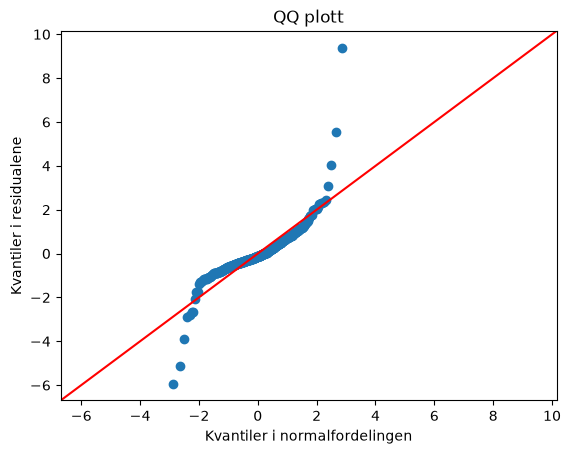

In [486]:
sns.scatterplot(x=resultat.fittedvalues, y=resultat.resid, s=8)
plt.xlabel("Predikert verdi")
plt.ylabel("Residual")
plt.axhline(0, color="black", linestyle="--")
plt.title("TA plott")
plt.show()

sm.qqplot(resultat.resid, line="45", fit=True)
plt.ylabel("Kvantiler i residualene")
plt.xlabel("Kvantiler i normalfordelingen")
plt.title("QQ plott")
plt.show()

I TA-plottet ligger de fleste residualene rundt 0 uten et tydelig mønster, men noen få punkter ligger veldig langt unna. QQ-plottet viser at residualene har tunge haler, altså mange flere ekstreme verdier enn normalfordelingen. Det ser vi også i summary, der kurtosis er 24,6.

Antakelsen om normalfordelte residualer holder derfor ikke. p-verdiene og konfidensintervallene må tolkes med forsiktighet.

In [487]:
pairs.loc[resultat.resid.abs().nlargest(7).index, ["name_prev", "name", "log_h_ratio", "log_w_ratio"]]

,name_prev,name,log_h_ratio,log_w_ratio
383,cosmog,cosmoem,-0.693147,9.210240
385,cosmoem,lunala,3.688879,-2.120164
56,haunter,gengar,-0.064539,6.003887
384,cosmoem,solgaleo,3.526361,-1.469576
455,tadbulb,bellibolt,1.386294,5.643679
420,corsola,cursola,0.510826,-2.525729
411,sizzlipede,centiskorch,1.455287,4.787492


Her ser du de sju største uteliggerne fra datasettet. Felles for dem er at kroppsformen endres helt i stedet for å skaleres opp. For eksempel går Cosmog fra 0,1 kg til 999,9 kg, og Haunter blir mye tyngre som Gengar uten å bli høyere.

In [488]:
# Studentiserte residualer: hvor ekstremt hvert punkt er, målt i standardavvik
stud_resid = resultat.get_influence().resid_studentized_external
uteliggere = abs(stud_resid) > 3

print("Antall uteliggere (|stud. residual| > 3):", uteliggere.sum())
print(pairs.loc[uteliggere, ["name_prev", "name", "log_h_ratio", "log_w_ratio"]])

uten_ute = pairs[~uteliggere]
resultat_uten = smf.ols("log_w_ratio ~ log_h_ratio", data=uten_ute).fit()
print(resultat_uten.summary())
print(resultat_uten.t_test("log_h_ratio = 3"))

Antall uteliggere (|stud. residual| > 3): 7
      name_prev         name  log_h_ratio  log_w_ratio
56      haunter       gengar    -0.064539     6.003887
383      cosmog      cosmoem    -0.693147     9.210240
384     cosmoem     solgaleo     3.526361    -1.469576
385     cosmoem       lunala     3.688879    -2.120164
411  sizzlipede  centiskorch     1.455287     4.787492
420     corsola      cursola     0.510826    -2.525729
455     tadbulb    bellibolt     1.386294     5.643679
                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.372
Model:                            OLS   Adj. R-squared:                  0.371
Method:                 Least Squares   F-statistic:                     281.3
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           6.38e-50
Time:                        13:37:19   Log-Likelihood:                -488.08
No. Observations:                 477   AI

For å sjekke sensitiviteten til modellen testet vi den på nytt uten de med studentisert residual over 3. Studentisert residual er residualen delt på standardavviket, altså hvor mange standardavvik punktet ligger fra linjen. Dersom den er over 3 standardavvik er det en uteligger, og vi fjernet 7 av dem.

Av dette så vi at stigningstallet økte til 1,27 med konfidensintervall [1,12, 1,42], og R² økte fra 0,11 til 0,37. Men det ligger fortsatt langt under β₁ = 3. Så hypotesen forkastes fortsatt.

In [489]:
resultat2 = smf.ols("log_w_ratio ~ log_h_ratio * normal", data=pairs).fit()
print(resultat2.summary())

# Tester om stigningstallet for normal type er 3
print(resultat2.t_test("log_h_ratio + log_h_ratio:normal = 3"))

# Samme modell uten de 7 uteliggerne
resultat2_uten = smf.ols("log_w_ratio ~ log_h_ratio * normal", data=uten_ute).fit()
print(resultat2_uten.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.126
Model:                            OLS   Adj. R-squared:                  0.121
Method:                 Least Squares   F-statistic:                     23.16
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           5.11e-14
Time:                        13:37:19   Log-Likelihood:                -658.60
No. Observations:                 484   AIC:                             1325.
Df Residuals:                     480   BIC:                             1342.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.8548      0

Slik vi ser her har pokemon av normal type et stigningstall på 0,66 + 1,07 = 1,74, mens andre typer har 0,66. Interaksjonsleddet log_h_ratio:normal er signifikant (p = 0,004), så normal typer ligger nærmere loven.

t-testen viser likevel at vi forkaster β₁ = 3 også for normal typer (p < 0,001), siden konfidensintervallet er [1,03, 2,44]. De følger altså loven bedre, men de følger den fortsatt ikke.

Uten de 7 uteliggerne er interaksjonsleddet ikke lenger signifikant (p = 0,056). Forskjellen mellom normal og andre typer kommer altså delvis av noen få ekstreme evolusjoner blant de andre typene.

Dette kan vi da bruke i klassifiseringen for å løse hypotese 2.

Hypotese 3 vil forutsette at stigningstallet B1 vil være nærmere 3 for tidlige generasjoner av pokemon.

In [490]:
pairs["gen"] = pairs["generation"].astype(int)
print(pairs["gen"].value_counts().sort_index())

gen
1    83
2    46
3    62
4    55
5    74
6    35
7    33
8    48
9    48
Name: count, dtype: int64


   gen   n  beta1  nedre  øvre
0    1  83   1.09   0.58  1.61
1    2  46   1.03   0.69  1.38
2    3  62   0.61   0.10  1.13
3    4  55   1.13   0.62  1.63
4    5  74   1.54   1.23  1.84
5    6  35   1.19   0.54  1.84
6    7  33  -0.66  -1.43  0.11
7    8  48   1.42   0.71  2.13
8    9  48   1.44   0.88  2.00


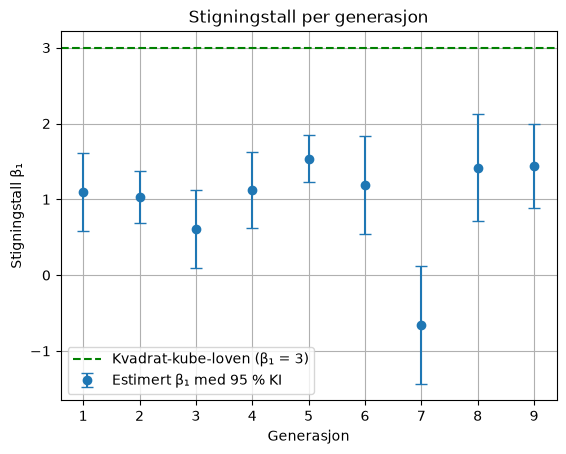

In [491]:
rader = []
for g, data_g in pairs.groupby("gen"):
    res_g = smf.ols("log_w_ratio ~ log_h_ratio", data=data_g).fit()
    ki = res_g.conf_int().loc["log_h_ratio"]
    rader.append({"gen": g, "n": len(data_g), "beta1": res_g.params["log_h_ratio"], "nedre": ki[0], "øvre": ki[1]})
per_gen = pd.DataFrame(rader)
print(per_gen.round(2))

plt.errorbar(per_gen["gen"], per_gen["beta1"], yerr=[per_gen["beta1"] - per_gen["nedre"], per_gen["øvre"] - per_gen["beta1"]], fmt="o", capsize=4, label="Estimert β₁ med 95 % KI")
plt.axhline(3, color="green", linestyle="--", label="Kvadrat-kube-loven (β₁ = 3)")
plt.xlabel("Generasjon")
plt.ylabel("Stigningstall β₁")
plt.title("Stigningstall per generasjon")
plt.legend()
plt.grid()
plt.show()

Stigningstallet ligger rundt 1–1,5 for nesten alle generasjoner, og ingen av konfidensintervallene inneholder 3. Grafen stiger litt for senere generasjoner. Generasjon 7 er den eneste med negativt stigningstall, og det kommer av Cosmog-linjen, som har tre av de største uteliggerne.

In [492]:
resultat3 = smf.ols("log_w_ratio ~ log_h_ratio * gen", data=pairs).fit()
print(resultat3.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     22.17
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.84e-13
Time:                        13:37:19   Log-Likelihood:                -659.91
No. Observations:                 484   AIC:                             1328.
Df Residuals:                     480   BIC:                             1345.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.4507      0.171     

I tilfellet hvor vi inkluderer alle pokemon er interaksjonsleddet log_h_ratio:gen negativt (−0,060). Det er riktig fortegn som stemmer overens med hypotesen, altså at stigningstallet synker for senere generasjoner.
p = 0,098 > 0,05, og konfidensintervallet [−0,13, 0,01] inneholder 0, så effekten er ikke signifikant.

For å sjekke hvor mye uteliggerne påvirker resultatet, fjerner vi de samme 7 uteliggerne som i hypotese 1 og 2.

In [493]:
# Samme modell uten de 7 uteliggerne (|studentisert residual| > 3)
# Lager uten_ute på nytt, siden gen-kolonnen ble lagt til i pairs etter at uten_ute ble laget
uten_ute = pairs[~uteliggere]
resultat3b = smf.ols("log_w_ratio ~ log_h_ratio * gen", data=uten_ute).fit()
print(resultat3b.summary())

                            OLS Regression Results                            
Dep. Variable:            log_w_ratio   R-squared:                       0.378
Model:                            OLS   Adj. R-squared:                  0.374
Method:                 Least Squares   F-statistic:                     95.62
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.20e-48
Time:                        13:37:19   Log-Likelihood:                -485.95
No. Observations:                 477   AIC:                             979.9
Df Residuals:                     473   BIC:                             996.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.3954      0.123     

Når vi fjerner de 7 uteliggerne, blir interaksjonsleddet log_h_ratio:gen positivt (0,028), men det er heller ikke signifikant (p = 0,31, konfidensintervall [−0,026, 0,082]).

Vi finner derfor ikke støtte for hypotese 3. Verken med eller uten uteliggerne er det en signifikant sammenheng mellom generasjon og hvor godt pokemon følger kvadrat-kube-loven.

## Oppsummering

Hypotese 1: Vi forkaster at β₁ = 3. Stigningstallet er 0,74, og 1,27 uten uteliggerne, så vekten øker langt mindre med høyden enn hva kvadrat-kube-loven tilsier.

Hypotese 2: Pokemon av normal type ligger nærmere loven (β₁ = 1,74) enn andre typer (β₁ = 0,66), men de følger den fortsatt ikke. Forskjellen er ikke lenger signifikant når vi fjerner uteliggerne. Klassifiseringen av hypotese 2 ligger i klassifisering.ipynb.

Hypotese 3: Vi finner ikke støtte for hypotesen. Trenden er ikke signifikant, verken med eller uten uteliggerne.